In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_log_error,
    root_mean_squared_error,
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor, ColumnTransformer

import matplotlib.pyplot as plt
import pandas as pd

import mlflow
import mlflow.sklearn
import os
import json

NUMERIC_NORMAL_FEATURES = ["dcoilwtico"]
CATEGORICAL_FEATURES = ["store_nbr", "family"]
NUMERIC_SKEWED_FEATURES = ["sales_lag15", "sales_lag30"]
TARGET = "sales"

COLUMNS_TO_KEEP = ["date", "family", "store_nbr", "is_int_sales"]

CUTOFFS_STR = ["2017-07-15", "2017-04-15", "2017-01-15", "2016-09-15"]
CUTOFFS_DATETIME = pd.to_datetime(CUTOFFS_STR)

HORIZON = 15

PATH_TRAIN_DF = "../data/processed/df_train.parquet"


def get_linear_regression_pipeline(skewed_feats, normal_feats, cat_feats):

    log_transformer = FunctionTransformer(np.log1p, validate=True)

    skewed_pipeline = Pipeline(
        steps=[("log", log_transformer), ("scaler", StandardScaler())]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num_skewed", skewed_pipeline, skewed_feats),
            ("num_normal", StandardScaler(), normal_feats),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats),
        ]
    )

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "model",
                TransformedTargetRegressor(
                    regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1
                ),
            ),
        ]
    )
    return model


def accuracy_evaluation(y_true, y_pred, cutoff):
    mae = mean_absolute_error(y_true=y_true, y_pred=y_pred)
    rmse = root_mean_squared_error(y_true=y_true, y_pred=y_pred)
    rmsle = root_mean_squared_log_error(y_true=y_true, y_pred=y_pred)

    print(
        f"Cutoff: {cutoff.date()}, MAE: {mae:.2f}, RMSE:{rmse:.2f}, RMSLE:{rmsle:.2f}"
    )

    return {"mae": mae, "rmse": rmse, "rmsle": rmsle}


def train_predict_evaluate(
    df: pd.DataFrame,
    model_builder_fn,
    cutoffs: list,
    horizon: int,
    skewed_feats: list,
    normal_feats: list,
    cat_feats: list,
    target: str,
    cols_to_keep: list,
):

    horizon_days = pd.Timedelta(days=horizon)

    results_list = []
    metrics_list = []

    features = skewed_feats + normal_feats + cat_feats

    for i, cutoff in enumerate(cutoffs):
        model = model_builder_fn(skewed_feats, normal_feats, cat_feats)

        train_df = df[df["date"] < cutoff]
        test_df = df[(df["date"] >= cutoff) & (df["date"] <= (cutoff + horizon_days))]

        X_train, X_test = train_df[features], test_df[features]
        y_train, y_test = train_df[target], test_df[target]

        model.fit(X_train, y_train)
        y_pred = np.clip(model.predict(X_test), a_min=0, a_max=None)

        res = X_test.copy()

        for col in cols_to_keep:
            res[col] = test_df[col]

        res["cutoff"] = cutoff
        res["y_true"] = y_test
        res["y_pred"] = y_pred

        mask = res["is_int_sales"] == True
        res.loc[mask, "y_pred"] = res.loc[mask, "y_pred"].round()

        fold_metrics = accuracy_evaluation(y_test, y_pred, cutoff)
        metrics_list.append(fold_metrics)
        results_list.append(res)

        mlflow.log_metric(f"rmsle_fold_{i+1}", fold_metrics["rmsle"])

    avg_rmsle = np.mean([m["rmsle"] for m in metrics_list])
    print(f"GLOBAL RMSLE: {avg_rmsle:.4f}")

    mlflow.log_metric("global_rmsle", avg_rmsle)
    mlflow.sklearn.log_model(sk_model=model, name="pipeline_model")

    df_results = pd.concat(results_list)
    return df_results


def plot_predictions(
    df: pd.DataFrame,
    df_results: pd.DataFrame,
    run_name: str,
    family_name: str = "AUTOMOTIVE",
    store_nbr_name: int = 20,
    cutoff: str = "2017-07-15",
):

    cutoff = pd.to_datetime(cutoff)

    df_results_filtered = df_results[
        (df_results["family"] == family_name)
        & (df_results["store_nbr"] == store_nbr_name)
        & (df_results["cutoff"] == cutoff)
    ]
    df_filtered = df[
        (df["family"] == family_name)
        & (df["store_nbr"] == store_nbr_name)
        & (df["date"] <= cutoff)
        & (df["date"] > (cutoff - pd.Timedelta(days=90)))
    ]

    plt.style.use("seaborn-v0_8-whitegrid")
    plt.figure(figsize=(16, 5))

    plt.plot(
        df_filtered["date"],
        df_filtered["sales"],
        color="#8c8c8c",
        linewidth=1,
        label="Historical Sales",
    )

    plt.plot(
        df_results_filtered["date"],
        df_results_filtered["y_true"],
        color="#005b96",
        linewidth=1,
        marker="o",
        markersize=3,
        label="Actual Sales",
    )

    plt.plot(
        df_results_filtered["date"],
        df_results_filtered["y_pred"],
        color="#e34a33",
        linewidth=1,
        linestyle="--",
        marker="X",
        markersize=3,
        label="Model Prediction",
    )

    plt.axvline(
        x=cutoff,
        color="red",
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
        label="Cutoff Date",
    )

    plt.title(
        f"Sales Prediction: {family_name.title()} | Store {store_nbr_name}",
        fontsize=15,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel("Date", fontsize=12, labelpad=10)
    plt.ylabel("Units Sold", fontsize=12, labelpad=10)

    plt.legend(loc="upper left", fontsize=10, frameon=True, shadow=True, borderpad=1)

    ax = plt.gca()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    os.makedirs("artifacts", exist_ok=True)
    plot_path = (
        f"artifacts/plot_predictions_{run_name}_{family_name}_{store_nbr_name}.png"
    )
    plt.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

    return plot_path


def run_experiment(
    model_name: str,
    skewed_feats: list,
    normal_feats: list,
    cat_feats: list,
    target: str,
    cols_to_keep: list,
    cutoffs: list,
    horizon: int,
    issue_name: str,
    version_name: str,
    df_path: str = "../data/processed/df_train.parquet",
    to_plot_family_name: str = "AUTOMOTIVE",
    to_plot_store_nbr_name: int = 20,
    to_plot_cutoff: str = "2017-07-15",
):
    df = pd.read_parquet(df_path)
    features = skewed_feats + normal_feats + cat_feats
    selected_model = MODEL_REGISTRY[model_name]
    run_name = f"{model_name}_{issue_name}_{version_name}"

    mlflow.set_tracking_uri("sqlite:///../mlflow.db")
    mlflow.set_experiment("Store_Sales_Forecasting")

    with mlflow.start_run(run_name=run_name):

        mlflow.set_tag("issue", issue_name)
        mlflow.set_tag("version", version_name)

        mlflow.log_param("model_type", model_name)
        mlflow.log_param("horizon_days", horizon)
        mlflow.log_param("total_features", len(features))
        mlflow.log_param("cutoff", [str(c.date()) for c in cutoffs])

        os.makedirs("artifacts", exist_ok=True)
        with open("artifacts/features_list.json", "w") as f:
            json.dump({"features": features}, f, indent=4)
        mlflow.log_artifact("artifacts/features_list.json", "metadata")

        mlflow.log_param("features_list", ", ".join(features))

        df_results = train_predict_evaluate(
            df,
            selected_model,
            cutoffs,
            horizon,
            skewed_feats,
            normal_feats,
            cat_feats,
            target,
            cols_to_keep,
        )

        plot_path = plot_predictions(
            df,
            df_results,
            run_name,
            to_plot_family_name,
            to_plot_store_nbr_name,
            to_plot_cutoff,
        )
        mlflow.log_artifact(plot_path, "visualizations")

    return df_results


MODEL_REGISTRY = {
    "linear_regression": get_linear_regression_pipeline,
    # "xgboost": get_xgboost_pipeline,
    # "random_forest": get_rf_pipeline,
}

Cutoff: 2017-07-15, MAE: 136.05, RMSE:497.51, RMSLE:0.55
Cutoff: 2017-04-15, MAE: 137.65, RMSE:523.56, RMSLE:0.78
Cutoff: 2017-01-15, MAE: 165.70, RMSE:633.25, RMSLE:0.87
Cutoff: 2016-09-15, MAE: 106.63, RMSE:406.81, RMSLE:0.58
GLOBAL RMSLE: 0.6925


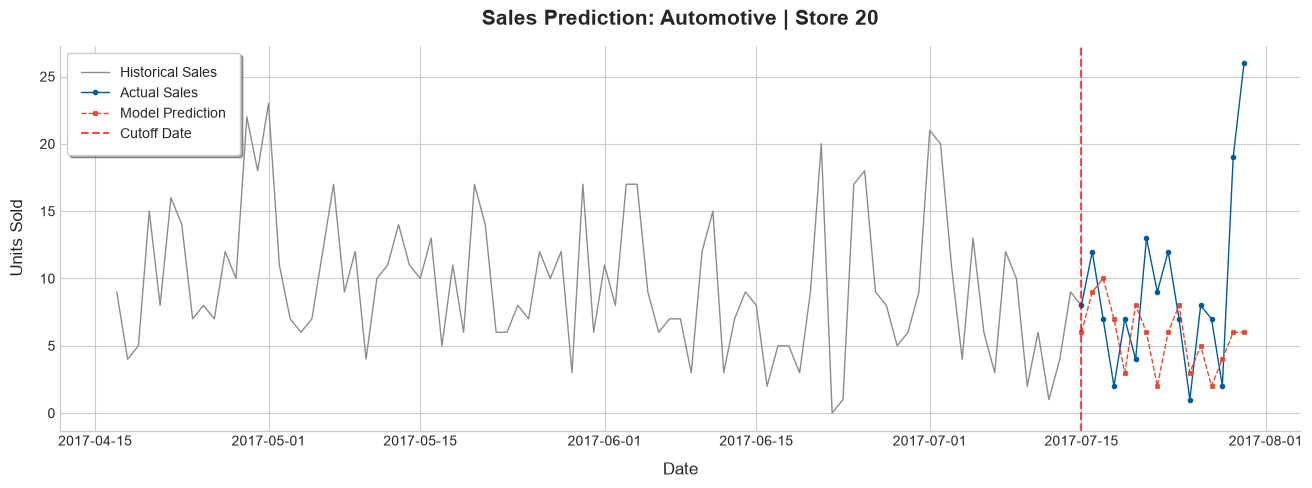

In [ ]:
ACTIVE_MODEL = "linear_regression"

ISSUE_NAME = "test"
VERSION_NAME = "v0"

df_results = run_experiment(
    model_name=ACTIVE_MODEL,
    skewed_feats=NUMERIC_SKEWED_FEATURES,
    normal_feats=NUMERIC_NORMAL_FEATURES,
    cat_feats=CATEGORICAL_FEATURES,
    target=TARGET,
    cols_to_keep=COLUMNS_TO_KEEP,
    cutoffs=CUTOFFS_DATETIME,
    horizon=HORIZON,
    issue_name=ISSUE_NAME,
    version_name=VERSION_NAME,
    df_path=PATH_TRAIN_DF,
)